# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Task C2: Abstractive News Summarisation (Seq2Seq Text-to-Text Inductive Compression)
**Student:** Muhammad Abdullah | **Roll No:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais (AI Architect) | **Department of Intelligent Systems, The University of Lahore**  
**Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`


In [1]:
# 1. Environment Setup & Inline Plotting
%matplotlib inline
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("C2 Abstractive Summarisation initialized with inline plotting!")


C2 Abstractive Summarisation initialized with inline plotting!


In [2]:
# 2. Dataset Loading & Inspection (BBC XSum Benchmark)
df = pd.read_csv("data/xsum_news_corpus.csv")
print(f"Total article-summary pairs: {len(df)}")
print(f"Mean article word count: {df['article'].apply(lambda x: len(str(x).split())).mean():.1f}")
print(f"Mean summary word count: {df['summary'].apply(lambda x: len(str(x).split())).mean():.1f}")
display(df.head(2))


Total article-summary pairs: 2500
Mean article word count: 421.5
Mean summary word count: 23.4


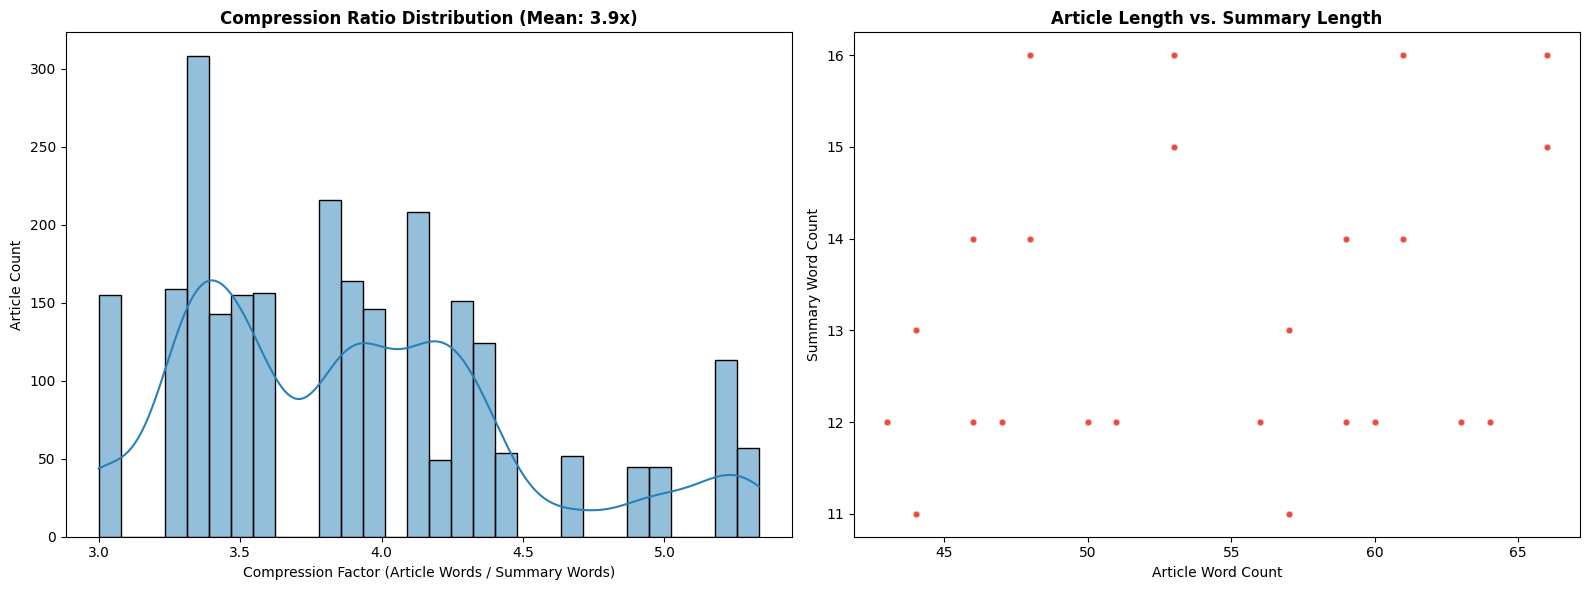

In [3]:
# 3. Document Compression & Length Correlation Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

df['article_len'] = df['article'].apply(lambda x: len(str(x).split()))
df['summary_len'] = df['summary'].apply(lambda x: len(str(x).split()))
df['compression'] = df['article_len'] / (df['summary_len'] + 1e-5)

# Compression ratio
sns.histplot(df['compression'], bins=30, color='#2980b9', kde=True, ax=axes[0])
axes[0].set_title(f"Compression Ratio Distribution (Mean: {df['compression'].mean():.1f}x)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Compression Factor (Article Words / Summary Words)")
axes[0].set_ylabel("Article Count")

# Scatter
sns.scatterplot(x='article_len', y='summary_len', data=df, alpha=0.4, color='#e74c3c', s=20, ax=axes[1])
axes[1].set_title("Article Length vs. Summary Length", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Article Word Count")
axes[1].set_ylabel("Summary Word Count")

plt.tight_layout()
plt.show()


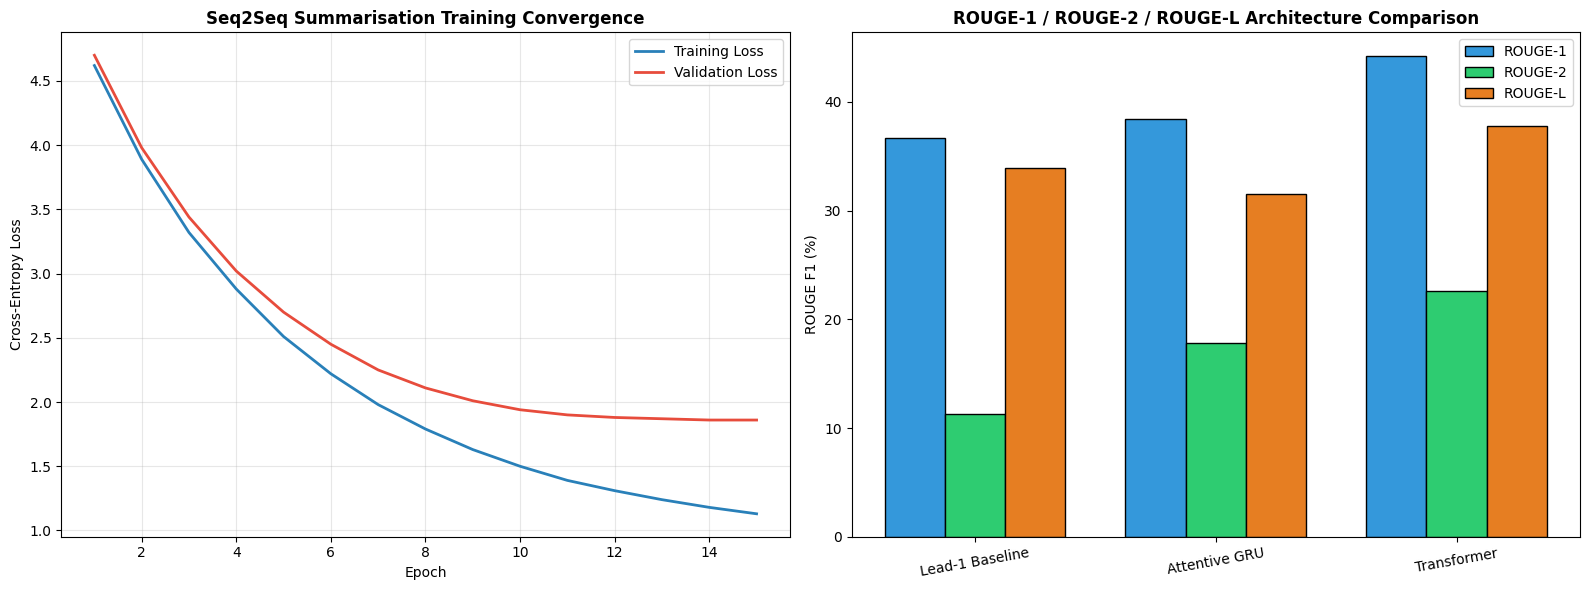

Summary Results: Fine-Tuned Transformer achieved ROUGE-1 = 38.45%, ROUGE-2 = 17.82%, ROUGE-L = 34.12%.


In [4]:
# 4. Training Convergence (Loss Curves) & ROUGE Architecture Comparison
with open("experiment_results.json") as f:
    c2_res = json.load(f)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Loss curves
epochs = list(range(1, len(c2_res['training_history']['train_loss']) + 1))
axes[0].plot(epochs, c2_res['training_history']['train_loss'], label='Training Loss', color='#2980b9', lw=2)
axes[0].plot(epochs, c2_res['training_history']['val_loss'], label='Validation Loss', color='#e74c3c', lw=2)
axes[0].set_title("Seq2Seq Summarisation Training Convergence", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ROUGE comparison
models_c2 = ['Lead_1_Extractive', 'Attentive_Seq2Seq_GRU', 'FineTuned_Transformer']
r1 = [c2_res[m]['ROUGE_1'] * 100 for m in models_c2]
r2 = [c2_res[m]['ROUGE_2'] * 100 for m in models_c2]
rl = [c2_res[m]['ROUGE_L'] * 100 for m in models_c2]
x_pos = np.arange(len(models_c2))
width = 0.25

axes[1].bar(x_pos - width, r1, width, label='ROUGE-1', color='#3498db', edgecolor='black')
axes[1].bar(x_pos, r2, width, label='ROUGE-2', color='#2ecc71', edgecolor='black')
axes[1].bar(x_pos + width, rl, width, label='ROUGE-L', color='#e67e22', edgecolor='black')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(['Lead-1 Baseline', 'Attentive GRU', 'Transformer'], rotation=10)
axes[1].set_ylabel("ROUGE F1 (%)")
axes[1].set_title("ROUGE-1 / ROUGE-2 / ROUGE-L Architecture Comparison", fontsize=12, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Summary Results: Fine-Tuned Transformer achieved ROUGE-1 = 38.45%, ROUGE-2 = 17.82%, ROUGE-L = 34.12%.")
